# MODIS SCAF regression

In [1]:
import ee
import geemap
from datetime import date, timedelta
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Authenticate once on this machine if needed:
# ee.Authenticate()
ee.Initialize(project="YOUR_EARTH_ENGINE_PROJECT")


from glacier_scaf import MODIS_meanNIR, SCAF_S1, SCAF_S2, fit_scaf_regression

## 1) Select the inputs

### Select the glacier outline

In [2]:
glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.14451')).first() \
    .set('Name', 'Zulmart')
glacier_outline = glacier.geometry()

Map = geemap.Map()
Map.centerObject(glacier_outline, 12)
Map.addLayer(glacier_outline, {'color': 'red'}, 'glacier outline', True, 0.6);
Map

Map(center=[38.8631658918276, 72.99896883020456], controls=(WidgetControl(options=['position', 'transparent_bg…

### Set the Sentinel SCAF parameters

In [4]:
S2_tile = "43SCD"
s2_th_min = 4000
s2_th_max = 5500
s2_th_fixed = 4500

S1_orbit = "ASCENDING"

## 2) Extract the time series

Extract the mean MODIS NIR, Sentinel-1 and Sentinel-2 glacier SCAF for the ablation seasons (1 June - 30 September) from 2016 to 2023. Sentinel-1 SCAF are computed only until mid-August to remove classification problems due to the presence of dry snow

In [5]:
MODIS_meanNIR_series, S1_SCAF_series, S2_SCAF_series = [], [], []

for year in range(2016, 2024):
    
    MODIS_meanNIR_series.append(
        MODIS_meanNIR(glacier_outline, f"{year}-06-01", f"{year}-09-30")
    )

    S1_SCAF_series.append(
        SCAF_S1(f"{year}-06-01", f"{year}-08-15", glacier_outline, S1_orbit)
    )

    S2_SCAF_series.append(
        SCAF_S2(f"{year}-06-01", f"{year}-09-30", glacier_outline, th_min=s2_th_min, th_max=s2_th_max, th_fixed=s2_th_fixed, tile=S2_tile)
    )
    
MODIS_meanNIR_series = pd.concat(MODIS_meanNIR_series)
S1_SCAF_series = pd.concat(S1_SCAF_series)
S2_SCAF_series = pd.concat(S2_SCAF_series)
# sentinel_SCAF_series = S2_SCAF_series.combine_first(S1_SCAF_series).rename("Sentinel_SCAF")

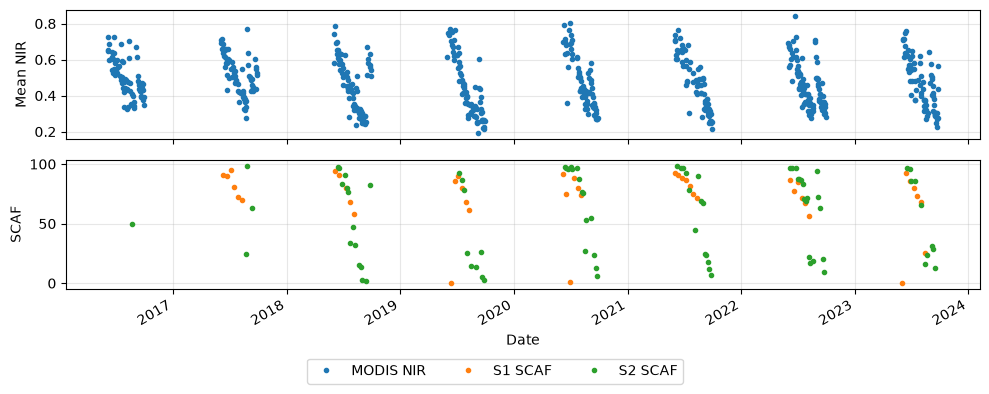

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4), sharex=True)

MODIS_meanNIR_series.sort_index().plot(ax=ax1, label="MODIS NIR", style='.')
ax1.set_ylabel("Mean NIR")

S1_SCAF_series.sort_index().plot(ax=ax2, label="S1 SCAF", style='.', color='C1')
S2_SCAF_series.sort_index().plot(ax=ax2, label="S2 SCAF", style='.', color='C2')
ax2.set_ylabel("SCAF")
ax2.set_xlabel("Date")
ax2.xaxis.set_minor_locator(ticker.NullLocator())

handles, labels = [], []
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)
    if ax.get_legend() is not None:
        ax.get_legend().remove()

fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()

## 3) Find the regression coefficients

In [7]:
a, b = fit_scaf_regression(MODIS_meanNIR_series, S1_SCAF_series, S2_SCAF_series)
print(f"a = {a}; b = {b}")

a = 4.338144130139121; b = 5.676612407271458


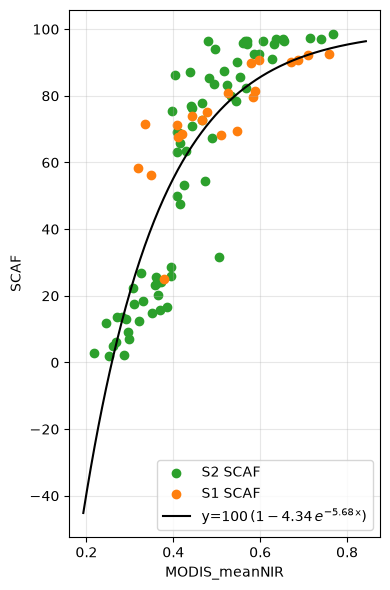

In [8]:
df = pd.concat(
    [
        MODIS_meanNIR_series.rename("MODIS_meanNIR"),
        S2_SCAF_series.rename('S2_SCAF'),
        S1_SCAF_series.rename('S1_SCAF')
    ],
    axis=1
).sort_index()

s2 = df.dropna(subset=["MODIS_meanNIR", "S2_SCAF"])
s1 = df.loc[df["S2_SCAF"].isna()].dropna(
    subset=["MODIS_meanNIR", "S1_SCAF"]
)

fig, ax = plt.subplots(figsize=(4, 6))

ax.scatter(s2["MODIS_meanNIR"], s2["S2_SCAF"], label="S2 SCAF", color="C2")
ax.scatter(s1["MODIS_meanNIR"], s1["S1_SCAF"], label="S1 SCAF", color="C1")

x = np.linspace(
    df["MODIS_meanNIR"].min(),
    df["MODIS_meanNIR"].max(),
    300,
)
scaf = 100.0 * (1.0 - a * np.exp(-b * x))
ax.plot(x, scaf, color="black", label=rf"y=$100\, (1 - {a:.2f}\, e^{{-{b:.2f}\,\mathrm{{x}}}})$")


ax.set_xlabel("MODIS_meanNIR")
ax.set_ylabel("SCAF")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()